# **Bagian A: Analisis Konseptual (Bobot: 20%)**

1. **Efek Regularisasi pada Batch Normalization (Slide 6–8)**

    Slide 8 menyebutkan bahwa Batch Normalization "acts like mild regularization" dan
    "often eliminates the need for Dropout".
    Jelaskan mekanisme statistik mini-batch yang menimbulkan efek regularisasi
    tersebut.

    Jawab:

    Batch Normalization bekerja dengan menormalisasi nilai aktivasi menggunakan rata-rata dan varians yang dihitung secara dinamis dari setiap mini-batch data (Ioffe & Szegedy, 2015; Slide 6-8). Karena mini-batch diambil secara acak, nilai statistik tersebut selalu bervariasi pada setiap iterasi, sehingga aktivasi satu gambar bergantung pada gambar lain di dalam batch yang sama. Variasi acak ini menimbulkan efek bising yang memaksa model mencari pola umum dan bertindak sebagai regularisasi ringan (Slide 8). Namun, asumsi menghilangkan Dropout ini tidak berlaku dan dapat memicu instabilitas pelatihan apabila kita menggunakan batch size yang sangat kecil sehingga estimasi statistiknya tidak stabil, atau ketika Batch Normalization dipakai bersamaan dengan Dropout yang dapat mengubah distribusi varians secara drastis antara fase training dan inferensi (Li dkk., 2019).


2. **Degradasi Jaringan Dalam dan Formulasi Residual (Slide 10–12)**

    Mengapa penambahan kedalaman lapisan pada plain CNN (tanpa sambungan residual)
    justru menurunkan akurasi pelatihan (degradation problem), padahal secara teoritis
    representasi model yang lebih dalam minimal dapat menyamai model dangkal via fungsi
    identitas (identity mapping)?
    Jelaskan bagaimana skip connection mengubah formulasi aliran gradien saat
    propagasi balik (backpropagation).
    Hubungkan mekanisme tersebut dengan mitigasi fenomena vanishing gradient yang
    telah dibahas pada Sesi 02.

    Jawab:

    Meskipun secara teori model yang lebih dalam minimal dapat menyamai model dangkal via fungsi identitas, dalam praktiknya plain CNN mengalami degradation problem di mana akurasi latih anjlok akibat kesulitan mengoptimalkan lapisan dalam (Slide 10-11). Hal ini diatasi oleh skip connection dalam arsitektur ResNet (He dkk., 2016; Slide 11-12), di mana jalur input ditambahkan ke output blok melalui formulasi y = F(x) + x. Saat backpropagation, turunan terhadap x menghasilkan penambahan suku identitas (+1) pada rantai perkalian gradien. Di plain network, gradien adalah perkalian berantai turunan kecil yang mengecil secara eksponensial seiring kedalaman (vanishing gradient dari Sesi 02). Jalur pintas ini menyediakan jalan pintas bagi gradien untuk mengalir langsung ke lapisan awal tanpa terhalang.


3. **Feature Extraction vs. Fine-Tuning (Slide 14–16)**

    Bandingkan pendekatan Feature Extraction (membekukan backbone) dengan FineTuning (membuka sebagian atau seluruh lapisan) ditinjau dari empat dimensi:
    Jumlah parameter yang diperbarui (trainable parameters).
    Kebutuhan volume data latih.
    Beban komputasi dan memori per epoch.
    Risiko rusaknya fitur representasi bawaan (destructive gradient updates).
    Sintesiskan kriteria praktis kapan masing-masing pendekatan paling tepat dipilih.

    Jawab:

    Pendekatan Feature Extraction membekukan seluruh backbone sehingga hanya melatih sedikit parameter pada head klasifikasi, sangat cocok untuk data latih yang sangat terbatas dan menghemat komputasi, namun berisiko kurang optimal jika domain datanya jauh dari ImageNet. Sebaliknya, Fine-Tuning membuka sebagian atau seluruh lapisan jaringan untuk diperbarui, sehingga membutuhkan volume data yang lebih besar, memori GPU serta komputasi yang lebih berat, serta rentan merusak representasi bawaan jika pembelajarannya terlalu agresif. Secara praktis, gunakan Feature Extraction sebagai langkah awal atau baseline yang cepat pada data kecil, dan beralihlah ke Fine-Tuning jika performa dasarnya masih kurang dan kita memiliki data tambahan yang cukup.


4. **Kaidah Penerapan Data Augmentation (Slide 20, 21, 23)**

    Jelaskan pertimbangan metodologis mengapa pipeline data augmentation hanya
    diaktifkan pada train set dan harus dinonaktifkan pada validation/test set.
    Berikan satu contoh teknik transformasi citra yang tidak layak digunakan untuk
    klasifikasi ras hewan peliharaan (pet breeds), dan jelaskan argumentasi
    ketidaklayakannya berdasarkan invariansi semantik label.

    Jawab:

    Data augmentation hanya diaktifkan pada train set dan wajib dimatikan pada validation atau test set agar evaluasi performa model tetap objektif dan jujur. Jika augmentasi aktif saat validasi, metrik akurasi akan terdistorsi karena model diuji pada data yang berubah-ubah secara acak. Contoh teknik yang tidak layak untuk klasifikasi ras hewan peliharaan adalah pembalikan vertikal atau upside down. Tindakan ini melanggar invariansi semantik label karena anjing atau kucing di dunia nyata tidak pernah berjalan dalam posisi terbalik, sehingga jika dibalik, model justru akan belajar fitur anatomi yang salah dan merusak pemahaman aslinya terhadap label kelas.
    

5. **Mitigasi Catastrophic Forgetting (Slide 28–29)**

    Slide 28 mengingatkan potensi terjadinya catastrophic forgetting apabila proses adaptasi
    model berlangsung terlalu agresif.
    Uraikan bagaimana fenomena hilangnya representasi bawaan tersebut terjadi.
    Jelaskan dua strategi mitigasi konkret (misalnya differential learning rate, gradual
    unfreezing, atau linear warmup) beserta alasan teoritis mengapa strategi tersebut
    efektif.

    Jawab:

    Catastrophic forgetting terjadi saat model beradaptasi terlalu agresif pada data baru, sehingga bobot dan fitur representasi dasar yang sudah bagus dari model pretrained mendadak rusak atau hilang. Untuk mencegahnya, kita bisa menggunakan differential learning rate, yaitu memberikan laju belajar yang sangat kecil pada lapisan dasar agar fitur lamanya tidak banyak berubah dan laju belajar yang lebih besar pada lapisan head yang baru. Strategi kedua adalah gradual unfreezing, yaitu membuka lapisan jaringan secara bertahap dari depan ke belakang mulai dari lapisan atas. Kedua cara ini efektif secara teoretis karena menjaga stabilitas pengetahuan awal model sambil memberikan ruang penyesuaian yang terkontrol pada domain baru.


# **Bagian B: Eksperimen Praktik (Bobot: 40%)**

In [20]:
import time # mengukur durasi training
import json # menyimpan log metrik (.json)
import random # seed Python built-in
import copy # menyimpan bobot model terbaik (early stopping)
from pathlib import Path # pengelolaan folder data & output

import numpy as np # operasi array + seed NumPy
import pandas as pd # tabel hasil & log .csv
import matplotlib.pyplot as plt # kurva loss & gambar misklasifikasi
from tqdm.auto import tqdm # progress bar saat training

import torch
import torch.nn as nn # layer (Linear) & loss (CrossEntropyLoss)
from torch.utils.data import Dataset, DataLoader, Subset # dataset custom, batching, subset indeks
from PIL import Image # membuka file gambar

from torchvision import datasets, models, transforms # dataset Pet, ResNet/EfficientNet, augmentasi

from sklearn.model_selection import train_test_split # split stratified 70/15/15
from sklearn.metrics import f1_score, classification_report, confusion_matrix # evaluasi

import torchvision, sklearn
print(f"PyTorch      : {torch.__version__}")
print(f"Torchvision  : {torchvision.__version__}")
print(f"Scikit-learn : {sklearn.__version__}")
print(f"NumPy        : {np.__version__}")
print(f"Pandas       : {pd.__version__}")

PyTorch      : 2.11.0+cu130
Torchvision  : 0.26.0+cu130
Scikit-learn : 1.6.1
NumPy        : 2.1.3
Pandas       : 2.2.3


In [19]:
# Hyperparameter & protokol
CONFIG = {
    "seed"         : 42,
    "img_size"     : 224,
    "batch_size"   : 32,
    "max_epochs"   : 30,
    "patience"     : 5,
    "weight_decay" : 1e-2,
    "lr_scratch"   : 1e-3,
    "lr_head"      : 1e-3,
    "lr_layer4"    : 1e-4,
    "split"        : {"train": 0.70, "val": 0.15, "test": 0.15},
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std" : [0.229, 0.224, 0.225],
    "num_workers"  : 2,
}

# Folderisasi
DATA_DIR   = Path("/content/data")
OUTPUT_DIR = Path("/content/output")
FIG_DIR    = OUTPUT_DIR / "figures"
LOG_DIR    = OUTPUT_DIR / "logs"
for d in [DATA_DIR, OUTPUT_DIR, FIG_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Reproduksibilitas
def set_seed(seed=CONFIG["seed"]):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG["device"] = torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu"

# Save konfigurasi
with open(LOG_DIR / "config.json", "w") as f:
    json.dump(CONFIG, f, indent=2)

print("Device :", CONFIG["device"])
print("Config tersimpan di:", LOG_DIR / "config.json")


Device : Tesla T4
Config tersimpan di: /content/output/logs/config.json


**Pemilihan Dataset**

Note:

*   Pakai dataset **Oxford-IIIT Pet**, langsung dari library `torchvision.datasets.OxfordIIITPet`
*   Dataset aslinya sudah dibagi dua sama pembuatnya (`trainval` dan `test`). Dua-duanya harus gabung dulu, karena tugas minta split sendiri dengan rasio 70/15/15.
*   Dari 37 ras, ambil **10 ras** biar kondisinya data terbatas: **5 kucing** dan **5 anjing**
*   Label aslinya 0-36, jadi ubah ke **0-9**. biar cocok sama output layer model (cuma punya 10 neuron).
*   Hasil filter: **1.987 gambar**, tiap kelas sekitar 200 gambar. Staffordshire (189) dan Abyssinian (198) sedikit lebih sedikit, jadi nanti pakai **Macro F1** supaya penilaian tiap kelas adil.
*   Data dibagi **stratified 70% train / 15% val / 15% test**, jadi proporsi tiap ras di ketiga bagian tetap seimbang.


100%|██████████| 792M/792M [00:30<00:00, 25.9MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.9MB/s]


DATASET OXFORD-IIIT PET: 37 kategori ras
 0. Abyssinian                    1. American Bulldog              2. American Pit Bull Terrier  
 3. Basset Hound                  4. Beagle                        5. Bengal                     
 6. Birman                        7. Bombay                        8. Boxer                      
 9. British Shorthair            10. Chihuahua                    11. Egyptian Mau               
12. English Cocker Spaniel       13. English Setter               14. German Shorthaired         
15. Great Pyrenees               16. Havanese                     17. Japanese Chin              
18. Keeshond                     19. Leonberger                   20. Maine Coon                 
21. Miniature Pinscher           22. Newfoundland                 23. Persian                    
24. Pomeranian                   25. Pug                          26. Ragdoll                    
27. Russian Blue                 28. Saint Bernard                29. Samoyed

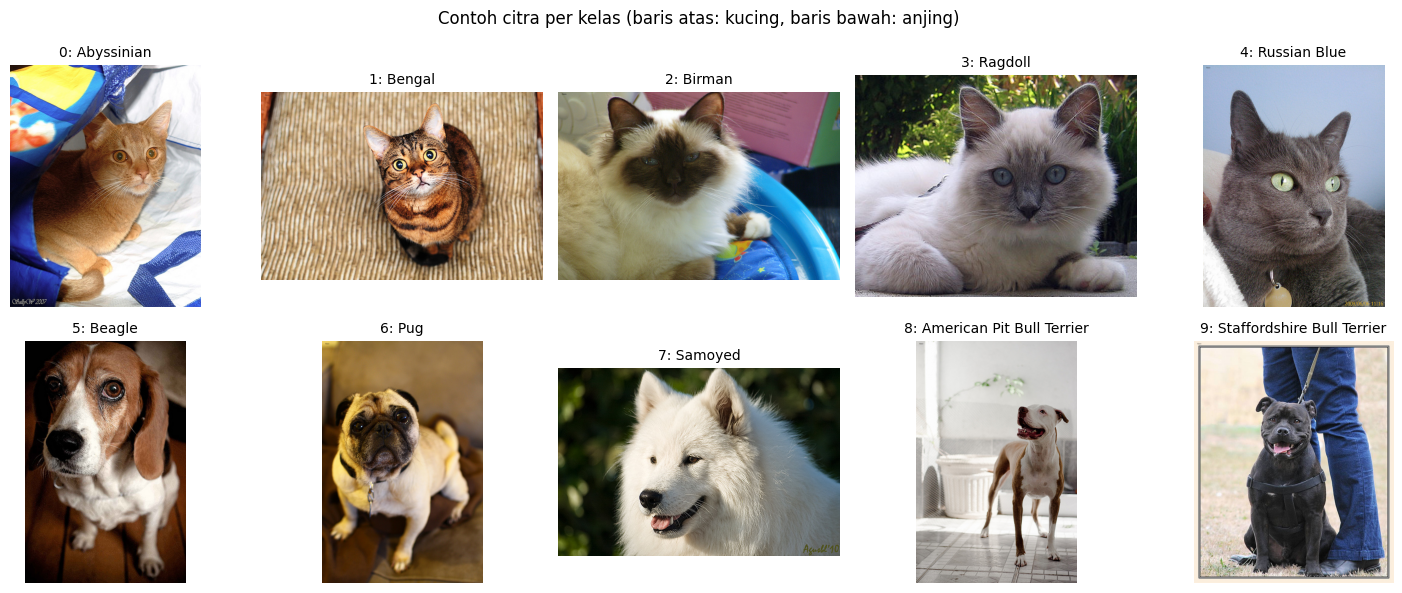

In [3]:
# Download Oxford-IIIT Pet (torchvision, tanpa autentikasi)
pet_trainval = datasets.OxfordIIITPet(root=DATA_DIR, split="trainval",
                                      target_types="category", download=True)
pet_test     = datasets.OxfordIIITPet(root=DATA_DIR, split="test",
                                      target_types="category", download=True)

# Daftar seluruh kategori (ditampilkan 3 kolom)
all_classes = pet_trainval.classes
print("=" * 90)
print(f"DATASET OXFORD-IIIT PET: {len(all_classes)} kategori ras")
print("=" * 90)
for i in range(0, len(all_classes), 3):
    print("  ".join(f"{i + j:2d}. {name:<27s}" for j, name in enumerate(all_classes[i:i + 3])))

# Gabungkan split bawaan (bakal di-split ulang 70:15:15)
all_paths  = list(pet_trainval._images) + list(pet_test._images)
all_labels = list(pet_trainval._labels) + list(pet_test._labels)

# Pilih 10 kelas: 5 kucing + 5 anjing
cat_classes = ["Abyssinian", "Bengal", "Birman", "Ragdoll", "Russian Blue"]
dog_classes = ["Beagle", "Pug", "Samoyed",
               "American Pit Bull Terrier", "Staffordshire Bull Terrier"]
selected_classes = cat_classes + dog_classes

assert len(cat_classes) == 5 and len(dog_classes) == 5, "Harus 5 kucing + 5 anjing"
for c in selected_classes:
    assert c in all_classes, f"Kelas '{c}' tidak ditemukan!"

# Filter data & petakan label asli (0-36) menjadi label baru (0-9)
old_to_new = {all_classes.index(c): i for i, c in enumerate(selected_classes)}

df = pd.DataFrame({"path": [str(p) for p in all_paths], "orig_label": all_labels})
df = df[df["orig_label"].isin(old_to_new)].reset_index(drop=True)
df["label"]      = df["orig_label"].map(old_to_new)
df["class_name"] = df["label"].map(lambda i: selected_classes[i])
df["species"]    = df["class_name"].map(lambda c: "cat" if c in cat_classes else "dog")

num_classes = len(selected_classes)
CONFIG["classes"] = selected_classes

assert num_classes == 10, "Tugas meminta tepat 10 kelas"

# Ringkasan
summary = (df.groupby(["species", "label", "class_name"]).size()
             .rename("jumlah").reset_index()
             .rename(columns={"species": "spesies", "label": "label", "class_name": "ras"}))
summary["persen"] = (summary["jumlah"] / len(df) * 100).round(1).astype(str) + "%"

print("\n" + "=" * 60)
print("10 KELAS TERPILIH")
print("=" * 60)
print(summary.to_string(index=False))
print("")
print("=" * 90)
print(f"Total data gambar : {len(df):,}   |   Jumlah kelas : {num_classes}"
      f"   |   Kucing : {(df['species'] == 'cat').sum():,}"
      f"   |   Anjing : {(df['species'] == 'dog').sum():,}")
print("=" * 90)
print("")

# Contoh 1 gambar per kelas (terpilih)
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for ax, (i, cname) in zip(axes.flat, enumerate(selected_classes)):
    sample = df[df["label"] == i].iloc[0]
    ax.imshow(Image.open(sample["path"]).convert("RGB"))
    ax.set_title(f"{i}: {cname}", fontsize=10)
    ax.axis("off")
plt.suptitle("Contoh citra per kelas (baris atas: kucing, baris bawah: anjing)")
plt.tight_layout()
plt.savefig(FIG_DIR / "sample_per_class.png", dpi=120)
plt.show()


**Split Data (Train : Val : Test)**

Note:

*   Dibagi **70% train : 15% val : 15% test** lewat 2 tahap `train_test_split`, karena fungsinya cuma bisa membagi jadi 2 bagian.
*   Pakai `stratify=label` supaya proporsi tiap ras tetap seimbang di ketiga split.
*   Pakai `random_state=seed` (42) supaya split selalu sama dan hasilnya bisa diulang.
*   Ada **cek data leakage** (`isdisjoint` + `assert`), jadi ga ada gambar yang sama di dua split.
*   Daftar split disimpan ke `data_split.csv` sebagai bukti reproduksibilitas.


In [4]:
seed = CONFIG["seed"] # 42

# Pisahkan 70% train dan 30% sisanya (temp)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=seed,
)

# Bagi temp menjadi 2 bagian sama besar (15% val, 15% test)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=seed,
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
test_df  = test_df.reset_index(drop=True)

# Cek kebocoran data (satu gambar tidak boleh muncul di lebih dari satu split)
tr_paths, va_paths, te_paths = set(train_df["path"]), set(val_df["path"]), set(test_df["path"])
assert tr_paths.isdisjoint(va_paths) and tr_paths.isdisjoint(te_paths) \
       and va_paths.isdisjoint(te_paths), "Ada data bocor antar split!"

# Ringkasan proporsi split
total = len(df)
print("=" * 60)
print(f"{'Split':<10s}{'Jumlah':<10s}{'Persen'}")
print("=" * 60)
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{name:<10s}{len(d):<10d}{len(d) / total:.1%}")
print(f"{'Total':<10s}{total:<10d}100.0%\n")

# Ringkasan jumlah citra per kelas
split_summary = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val"  : val_df["class_name"].value_counts(),
    "test" : test_df["class_name"].value_counts(),
}).loc[selected_classes]
split_summary["total"] = split_summary.sum(axis=1)

print("" + "=" * 60)
print("JUMLAH CITRA PER KELAS")
print("=" * 60)
print(f"{'Ras':<30s}{'Train':<8s}{'Val':<8s}{'Test':<8s}{'Total'}")
print("=" * 60)
for ras, r in split_summary.iterrows():
    print(f"{ras:<30s}{r['train']:<8d}{r['val']:<8d}{r['test']:<8d}{r['total']}")
print("-" * 60)
print(f"{'Total':<30s}{split_summary['train'].sum():<8d}{split_summary['val'].sum():<8d}"
      f"{split_summary['test'].sum():<8d}{split_summary['total'].sum()}")

# Simpan daftar split (bukti reproduksibilitas)
split_log = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test"),
], ignore_index=True)
split_log.to_csv(LOG_DIR / "data_split.csv", index=False)

print(f"\nDaftar split tersimpan di: {LOG_DIR / 'data_split.csv'}")


Split     Jumlah    Persen
Train     1390      70.0%
Val       298       15.0%
Test      299       15.0%
Total     1987      100.0%

JUMLAH CITRA PER KELAS
Ras                           Train   Val     Test    Total
Abyssinian                    138     30      30      198
Bengal                        140     30      30      200
Birman                        140     30      30      200
Ragdoll                       140     30      30      200
Russian Blue                  140     30      30      200
Beagle                        140     30      30      200
Pug                           140     30      30      200
Samoyed                       140     30      30      200
American Pit Bull Terrier     140     30      30      200
Staffordshire Bull Terrier    132     28      29      189
------------------------------------------------------------
Total                         1390    298     299     1987

Daftar split tersimpan di: /content/output/logs/data_split.csv


**Transforms, Dataset & DataLoader**

Note:

*   Ada **3 pipeline transform**: `train_tf_aug` (train dengan augmentasi), `train_tf_noaug` (train tanpa augmentasi, untuk B4), dan `eval_tf` (val dan test, tanpa augmentasi).
*   Augmentasi hanya dipakai di **data train**: RandomResizedCrop, HorizontalFlip, Rotation 15°, dan ColorJitter. Val dan test tetap asli supaya evaluasinya jujur.
*   Semua gambar di-resize ke **224 x 224** dan dinormalisasi pakai **mean dan std ImageNet**, sesuai protokol tugas dan bobot pretrained ResNet-18.
*   `PetDataset` dibuat sendiri supaya train, val, dan test bisa **pakai transform yang berbeda**. `.convert("RGB")` memastikan semua gambar punya 3 channel.
*   `DataLoader` pakai **batch size 32**. Hanya train yang di-**shuffle**.
*   Reproduksibilitas: urutan shuffle dikunci pakai `generator` dan `seed_worker`, jadi urutan data dan augmentasi sama tiap run.
*   `make_loaders()` dibuat sebagai fungsi dan dipanggil ulang di awal tiap eksperimen, jadi semua kondisi (B1-B5) mulai dari urutan data yang sama.
*   Sanity check: 1 batch berbentuk **(32, 3, 224, 224)**, dengan jumlah batch **44 (train) / 10 (val) / 10 (test)**.


DATALOADER
Shape batch gambar    : (32, 3, 224, 224)
Shape batch label     : (32,)
Batch size            : 32
Ukuran input          : 224 x 224

Split     Citra     Batch
Train     1390      44
Val       298       10
Test      299       10



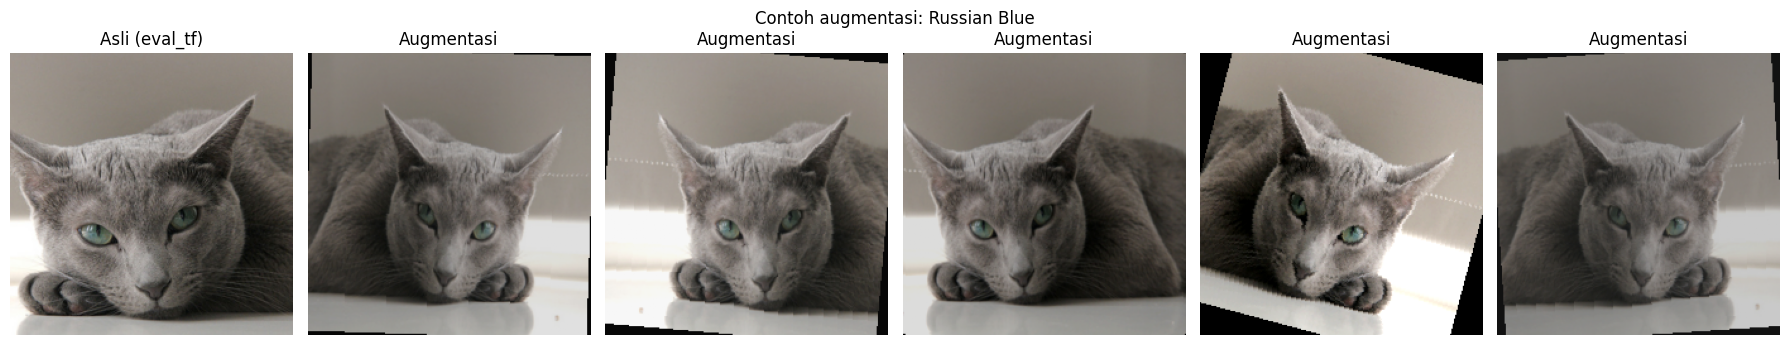

In [5]:
# Transforms, Dataset & Dataloader

MEAN, STD = CONFIG["imagenet_mean"], CONFIG["imagenet_std"]
IMG = CONFIG["img_size"]

# Transform data train DENGAN augmentasi
train_tf_aug = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Transform data train TANPA augmentasi
train_tf_noaug = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Transform validasi dan test (deterministik, tanpa augmentasi)
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Dataset custom: baca gambar dari path di DataFrame
class PetDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths     = frame["path"].tolist()
        self.labels    = frame["label"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert("RGB")
        return self.transform(img), self.labels[idx]

# Seed untuk worker DataLoader (reproduksibilitas augmentasi)
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

# Pembuat DataLoader (dipanggil ulang di awal tiap eksperimen)
def make_loaders(augment=True, seed=CONFIG["seed"]):
    g = torch.Generator()
    g.manual_seed(seed)

    train_ds = PetDataset(train_df, train_tf_aug if augment else train_tf_noaug)
    val_ds   = PetDataset(val_df,  eval_tf)
    test_ds  = PetDataset(test_df, eval_tf)

    common = dict(batch_size=CONFIG["batch_size"], num_workers=CONFIG["num_workers"],
                  pin_memory=True, worker_init_fn=seed_worker)

    train_loader = DataLoader(train_ds, shuffle=True,  generator=g, **common)
    val_loader   = DataLoader(val_ds,   shuffle=False, **common)
    test_loader  = DataLoader(test_ds,  shuffle=False, **common)
    return train_loader, val_loader, test_loader

# Sanity check: bentuk satu batch dan jumlah batch
set_seed()
train_loader, val_loader, test_loader = make_loaders(augment=True)
images, labels = next(iter(train_loader))

print("=" * 50)
print("DATALOADER")
print("=" * 50)
print(f"{'Shape batch gambar':<22s}: {tuple(images.shape)}")
print(f"{'Shape batch label':<22s}: {tuple(labels.shape)}")
print(f"{'Batch size':<22s}: {CONFIG['batch_size']}")
print(f"{'Ukuran input':<22s}: {IMG} x {IMG}\n")
print("=" * 30)
print(f"{'Split':<10s}{'Citra':<10s}{'Batch'}")
print("=" * 30)
for name, d, ld in [("Train", train_df, train_loader),
                    ("Val", val_df, val_loader),
                    ("Test", test_df, test_loader)]:
    print(f"{name:<10s}{len(d):<10d}{len(ld)}")

print("")

# Fungsi untuk mengembalikan tensor ternormalisasi menjadi gambar biasa
def denorm(t):
    t = t * torch.tensor(STD).view(3, 1, 1) + torch.tensor(MEAN).view(3, 1, 1)
    return t.clamp(0, 1).permute(1, 2, 0).numpy()

# Visualisasi: gambar yang sama, tanpa vs dengan augmentasi
sample_img = Image.open(train_df.loc[0, "path"]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(denorm(eval_tf(sample_img)))
axes[0].set_title("Asli (eval_tf)")
for ax in axes[1:]:
    ax.imshow(denorm(train_tf_aug(sample_img)))
    ax.set_title("Augmentasi")
for ax in axes:
    ax.axis("off")
plt.suptitle(f"Contoh augmentasi: {train_df.loc[0, 'class_name']}")
plt.tight_layout()
plt.savefig(FIG_DIR / "augmentation_preview.png", dpi=120)
plt.show()


**Fungsi Model, Training, Evaluasi & Logging**

Note:

*   `build_model` membuat model sesuai strategi: **scratch** (B1, bobot acak, semua layer dilatih), **feature_extract** (B2, backbone beku, hanya `fc` dilatih), dan **finetune** (B3, `layer4` + `fc` dilatih). Head diganti jadi **10 output** dan bobot pretrained memakai `IMAGENET1K_V1`.
*   **Differential learning rate** untuk B3: `layer4` pakai lr kecil (1e-4) supaya fitur pretrained tidak rusak, `fc` pakai lr besar (1e-3). Optimizer-nya **AdamW** dengan weight decay 1e-2.
*   `set_train_mode` menjaga **BatchNorm yang dibekukan tetap di mode eval**, supaya statistik ImageNet-nya tidak berubah. Dengan begini backbone di B2 benar-benar beku.
*   `run_epoch` menjalankan satu epoch. Kalau ada optimizer, mode train (forward, loss, backward, update). Kalau tidak, mode evaluasi tanpa gradien.
*   **Early stopping** memantau **val loss** dengan patience 5. Bobot terbaik disimpan lewat `deepcopy` dan dimuat ulang sebelum evaluasi test, jadi yang dites adalah model terbaik, bukan model epoch terakhir.
*   `set_seed()` dan `make_loaders()` dipanggil di awal tiap eksperimen, jadi semua kondisi mulai dari titik yang sama dan perbandingannya adil.
*   Metrik yang dicatat tiap eksperimen: trainable params, learning rate per grup, epoch konvergen, durasi training, val acc, test acc, dan **Macro F1 test**.
*   Hasil disimpan otomatis tiap eksperimen selesai ke `results_summary.csv/json` dan `history_all.csv` (log mentah untuk laporan), serta bobot model ke `model_<id>.pt`.
*   Sanity check: trainable params harus **11.181.642 (B1) / 5.130 (B2) / 8.398.858 (B3)**.


In [6]:
# FUNGSI MODEL, TRAINING, EVALUASI & LOGGING

ALL_RESULTS = {}   # ringkasan semua eksperimen (B1 sampai B5)
ALL_HISTORY = {}   # riwayat per-epoch semua eksperimen

# Build model
def build_model(strategy, arch="resnet18"):
    """
    strategy: "scratch"         = B1: bobot acak, semua layer dilatih
              "feature_extract" = B2: backbone beku, hanya head dilatih
              "finetune"        = B3: blok terakhir + head dilatih (differential LR)
    """
    pretrained = strategy != "scratch"

    if arch == "resnet18":
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        model = models.resnet18(weights=weights)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        head, last_block = model.fc, model.layer4
    elif arch == "efficientnet_b0": # untuk B5
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        model = models.efficientnet_b0(weights=weights)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
        head, last_block = model.classifier, model.features[-2:]
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    # Kondisi buat atur bagian mana yang dibekukan
    if strategy == "scratch":
        for p in model.parameters():
            p.requires_grad = True
        groups = [{"name": "all_layers", "params": list(model.parameters()),
                   "lr": CONFIG["lr_scratch"]}]

    elif strategy == "feature_extract":
        for p in model.parameters():
            p.requires_grad = False
        for p in head.parameters():
            p.requires_grad = True
        groups = [{"name": "head", "params": list(head.parameters()),
                   "lr": CONFIG["lr_head"]}]

    elif strategy == "finetune":
        for p in model.parameters():
            p.requires_grad = False
        for p in list(last_block.parameters()) + list(head.parameters()):
            p.requires_grad = True
        groups = [{"name": "last_block", "params": list(last_block.parameters()),
                   "lr": CONFIG["lr_layer4"]},
                  {"name": "head", "params": list(head.parameters()),
                   "lr": CONFIG["lr_head"]}]
    else:
        raise ValueError(f"Strategi tidak dikenal: {strategy}")

    optimizer = torch.optim.AdamW(groups, weight_decay=CONFIG["weight_decay"])

    info = {
        "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "total_params"    : sum(p.numel() for p in model.parameters()),
        "lr_groups"       : {g["name"]: g["lr"] for g in optimizer.param_groups},
    }
    return model.to(device), optimizer, info

# Set train mode untuk freeze layer
def set_train_mode(model):
    """BatchNorm yang dibekukan tetap di mode eval agar statistik ImageNet-nya tidak berubah."""
    model.train()
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            if not any(p.requires_grad for p in m.parameters(recurse=False)):
                m.eval()

# Menjalankan 1 epoch
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    set_train_mode(model) if is_train else model.eval()

    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(is_train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            out  = model(x)
            loss = criterion(out, y)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * x.size(0)
            correct    += (out.argmax(dim=1) == y).sum().item()
            n          += x.size(0)
    return total_loss / n, correct / n

# Prediksi Lengkap (Test Set dan Failure Analysis)
@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_y, all_pred, all_prob = [], [], []
    for x, y in loader:
        prob = torch.softmax(model(x.to(device)), dim=1).cpu()
        all_prob.append(prob)
        all_pred.append(prob.argmax(dim=1))
        all_y.append(y)
    return torch.cat(all_y).numpy(), torch.cat(all_pred).numpy(), torch.cat(all_prob).numpy()

# Simpan hasil ke disk (dipanggil tiap eksperimen selesai)
def save_all_logs():
    pd.DataFrame(ALL_RESULTS.values()).to_csv(LOG_DIR / "results_summary.csv", index=False)
    with open(LOG_DIR / "results_summary.json", "w") as f:
        json.dump(list(ALL_RESULTS.values()), f, indent=2)
    pd.concat(ALL_HISTORY.values(), ignore_index=True).to_csv(LOG_DIR / "history_all.csv", index=False)

# Jalankan 1 eksperimen lengkap
def run_experiment(exp_id, strategy, arch="resnet18", augment=True, description=""):
    set_seed() # titik awal sama untuk semua eksperimen
    train_loader, val_loader, test_loader = make_loaders(augment=augment)
    model, optimizer, info = build_model(strategy, arch)
    criterion = nn.CrossEntropyLoss()

    # Tabel konfigurasi eksperimen
    print("=" * 70)
    print(f"EKSPERIMEN {exp_id}: {description}")
    print("=" * 70)
    print(f"{'Strategi':<20s}: {strategy}")
    print(f"{'Arsitektur':<20s}: {arch}")
    print(f"{'Augmentasi':<20s}: {augment}")
    print(f"{'Trainable params':<20s}: {info['trainable_params']:,} / {info['total_params']:,}")
    print(f"{'Learning rate':<20s}: {info['lr_groups']}")
    print()

    # Tabel progres training per epoch
    print("=" * 70)
    print(f"{'Epoch':<8s}{'Train Loss':<12s}{'Train Acc':<12s}{'Val Loss':<12s}{'Val Acc':<12s}{'Waktu':<9s}{'Catatan'}")
    print("=" * 70)

    history, best_val_loss, best_epoch, wait = [], float("inf"), 0, 0
    best_state = None
    t0 = time.time()

    for epoch in range(1, CONFIG["max_epochs"] + 1):
        te = time.time()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        epoch_time = time.time() - te

        history.append({"exp_id": exp_id, "epoch": epoch,
                        "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va_loss, "val_acc": va_acc,
                        "epoch_time_s": epoch_time})

        improved = va_loss < best_val_loss - 1e-4
        if improved:
            best_val_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1

        print(f"{epoch:<8d}{tr_loss:<12.4f}{tr_acc:<12.3f}{va_loss:<12.4f}{va_acc:<12.3f}"
              f"{f'{epoch_time:.1f}s':<9s}{'best' if improved else ''}")

        if wait >= CONFIG["patience"]:
            print("=" * 70)
            print(f"Early stopping: val loss tidak membaik {CONFIG['patience']} epoch berturut-turut.")
            break
    print()

    train_time = time.time() - t0

    # Evaluasi memakai bobot TERBAIK
    model.load_state_dict(best_state)
    y_true, y_pred, y_prob = predict(model, test_loader)
    best_row = history[best_epoch - 1]

    result = {
        "exp_id"          : exp_id,
        "description"     : description,
        "arch"            : arch,
        "strategy"        : strategy,
        "augment"         : augment,
        "trainable_params": info["trainable_params"],
        "total_params"    : info["total_params"],
        "lr_groups"       : json.dumps(info["lr_groups"]),
        "epochs_run"      : len(history),
        "best_epoch"      : best_epoch,
        "train_time_s"    : round(train_time, 1),
        "time_per_epoch_s": round(train_time / len(history), 1),
        "best_val_loss"   : round(best_val_loss, 4),
        "train_acc_best"  : round(best_row["train_acc"], 4),
        "val_acc_best"    : round(best_row["val_acc"], 4),
        "gap_train_val"   : round(best_row["train_acc"] - best_row["val_acc"], 4),
        "test_acc"        : round(float((y_true == y_pred).mean()), 4),
        "test_macro_f1"   : round(f1_score(y_true, y_pred, average="macro"), 4),
    }

    ALL_RESULTS[exp_id] = result
    ALL_HISTORY[exp_id] = pd.DataFrame(history)
    save_all_logs()
    torch.save(best_state, OUTPUT_DIR / f"model_{exp_id}.pt")

    # Tabel hasil akhir eksperimen
    print("=" * 70)
    print(f"HASIL {exp_id}")
    print("=" * 70)
    print(f"{'Best epoch':<20s}: {best_epoch} dari {len(history)} epoch")
    print(f"{'Val acc':<20s}: {result['val_acc_best']:.3f}")
    print(f"{'Test acc':<20s}: {result['test_acc']:.3f}")
    print(f"{'Test macro F1':<20s}: {result['test_macro_f1']:.3f}")
    print(f"{'Waktu training':<20s}: {train_time / 60:.1f} menit")
    print("=" * 70)
    return model, result, (y_true, y_pred, y_prob)

# Display Jumlah Trainable Params Tiap Strategi
print("=" * 90)
print(f"{'Strategi':<20s}{'Trainable':<16s}{'Total':<16s}{'Learning rate'}")
print("=" * 90)
for s in ["scratch", "feature_extract", "finetune"]:
    _, _, inf = build_model(s)
    print(f"{s:<20s}{inf['trainable_params']:<16,d}{inf['total_params']:<16,d}{inf['lr_groups']}")
print("=" * 90)
del _
torch.cuda.empty_cache()


Strategi            Trainable       Total           Learning rate
scratch             11,181,642      11,181,642      {'all_layers': 0.001}
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 72.6MB/s]


feature_extract     5,130           11,181,642      {'head': 0.001}
finetune            8,398,858       11,181,642      {'last_block': 0.0001, 'head': 0.001}


**B1: Baseline From Scratch**

Note:

*   B1 adalah **tolok ukur batas bawah**: ResNet-18 dengan bobot acak (`weights=None`), tanpa pretrained.
*   **Semua layer dilatih** (11.181.642 parameter) dengan lr 1e-3 dan augmentasi aktif.
*   Tujuannya melihat seberapa jauh model bisa belajar dari 1.390 gambar saja, lalu dibandingkan dengan B2 dan B3 yang memakai bobot ImageNet.
*   Hasil diharapkan jauh di bawah transfer learning (Slide 15). Kalau val loss naik-turun dan train acc rendah, itu tanda model belum cukup belajar (underfitting), bukan overfitting.

In [7]:
# B1: Baseline From Scratch
model_B1, res_B1, pred_B1 = run_experiment(
    exp_id="B1", strategy="scratch", augment=True,
    description="ResNet-18 dari inisialisasi acak",
)


EKSPERIMEN B1: ResNet-18 dari inisialisasi acak
Strategi            : scratch
Arsitektur          : resnet18
Augmentasi          : True
Trainable params    : 11,181,642 / 11,181,642
Learning rate       : {'all_layers': 0.001}

Epoch   Train Loss  Train Acc   Val Loss    Val Acc     Waktu    Catatan
1       2.3516      0.177       2.5239      0.232       16.4s    best
2       2.0746      0.253       1.9927      0.289       13.8s    best
3       1.9466      0.323       1.9447      0.315       13.9s    best
4       1.8470      0.352       1.8786      0.339       14.2s    best
5       1.7758      0.380       2.7060      0.279       13.9s    
6       1.6750      0.429       2.1918      0.319       13.9s    
7       1.6258      0.440       1.7316      0.379       13.9s    best
8       1.5381      0.464       2.1529      0.319       13.5s    
9       1.5670      0.452       1.7841      0.403       13.8s    
10      1.4011      0.525       2.3232      0.376       13.7s    
11      1.4122      

**B2: Feature Extraction**

Note:

*   ResNet-18 **pretrained ImageNet**, seluruh backbone **dibekukan** (`requires_grad=False`). Hanya layer `fc` baru (512 → 10) yang dilatih.
*   Trainable parameters hanya **5.130** (512 × 10 bobot + 10 bias), Learning rate 1e-3, augmentasi aktif.
*   BatchNorm di backbone dijaga tetap mode eval, jadi fitur ImageNet benar-benar tidak berubah.
*   Diharapkan jauh lebih baik dari B1 walau parameter yang dilatih jauh lebih sedikit, karena fitur visual dari ImageNet bisa dipakai ulang.


In [8]:
# B2: W. Feature Extarction
model_B2, res_B2, pred_B2 = run_experiment(
    exp_id="B2", strategy="feature_extract", augment=True,
    description="ResNet-18 pretrained, backbone beku, hanya fc dilatih",
)


EKSPERIMEN B2: ResNet-18 pretrained, backbone beku, hanya fc dilatih
Strategi            : feature_extract
Arsitektur          : resnet18
Augmentasi          : True
Trainable params    : 5,130 / 11,181,642
Learning rate       : {'head': 0.001}

Epoch   Train Loss  Train Acc   Val Loss    Val Acc     Waktu    Catatan
1       1.3393      0.577       0.6900      0.792       18.5s    best
2       0.5664      0.852       0.4599      0.862       12.6s    best
3       0.4056      0.889       0.3849      0.876       12.8s    best
4       0.3401      0.906       0.3734      0.869       12.7s    best
5       0.2986      0.921       0.3240      0.883       12.3s    best
6       0.2842      0.912       0.3157      0.879       12.1s    best
7       0.2540      0.925       0.2888      0.896       12.0s    best
8       0.2374      0.926       0.3186      0.872       12.9s    
9       0.2325      0.919       0.3022      0.879       13.3s    
10      0.2171      0.927       0.2901      0.889       13.4

**B3: Progressive Fine-Tuning**

Note:

*   ResNet-18 **pretrained ImageNet**. Yang dilatih -> blok residual terakhir (`layer4`) dan `fc` (**8.398.858** parameter). Layer sebelumnya tetap beku.
*   Pakai **differential learning rate**: `layer4` lr 1e-4, `fc` lr 1e-3. `layer4` diubah pelan supaya fitur pretrained tidak rusak (catastrophic forgetting, Slide 28).
*   Augmentasi aktif, sama seperti B1 dan B2, jadi perbandingan ketiganya adil.
*   Tujuannya melihat apakah menyesuaikan fitur tingkat tinggi ke domain hewan peliharaan lebih baik daripada feature extraction murni (B2).

In [9]:
# B3: Progresive Fine-Tuning

model_B3, res_B3, pred_B3 = run_experiment(
    exp_id="B3", strategy="finetune", augment=True,
    description="ResNet-18 pretrained, layer4 + fc dilatih (differential LR)",
)


EKSPERIMEN B3: ResNet-18 pretrained, layer4 + fc dilatih (differential LR)
Strategi            : finetune
Arsitektur          : resnet18
Augmentasi          : True
Trainable params    : 8,398,858 / 11,181,642
Learning rate       : {'last_block': 0.0001, 'head': 0.001}

Epoch   Train Loss  Train Acc   Val Loss    Val Acc     Waktu    Catatan
1       0.7598      0.774       0.3263      0.876       12.4s    best
2       0.2304      0.915       0.2504      0.889       11.9s    best
3       0.1341      0.956       0.2040      0.913       12.1s    best
4       0.0883      0.981       0.2044      0.916       12.8s    
5       0.0629      0.983       0.2149      0.926       12.7s    
6       0.0644      0.982       0.2097      0.909       12.8s    
7       0.0373      0.991       0.3161      0.886       12.8s    
8       0.0273      0.996       0.2799      0.913       12.7s    
Early stopping: val loss tidak membaik 5 epoch berturut-turut.

HASIL B3
Best epoch          : 3 dari 8 epoch
Val acc

**B4: Uji Kontrol Data Augmentation**

Note:

*   B4 adalah **B3 yang dijalankan ulang tanpa augmentasi**. Train hanya memakai Resize, CenterCrop, dan Normalisasi.
*   Semua pengaturan lain **identik dengan B3** (strategi, learning rate, seed, split), jadi satu-satunya variabel yang berbeda adalah augmentasi.
*   Pembanding "dengan augmentasi" adalah hasil B3, jadi tidak perlu eksperimen tambahan.
*   Yang dibandingkan: selisih akurasi dan **generalization gap** (train acc dikurangi val acc). Supaya adil, gap dihitung dengan akurasi train dari gambar asli (Cell 11 bagian 4).
*   Val dan test tetap tanpa augmentasi di kedua kondisi, jadi tidak ada data leakage.

In [10]:
# B4: Uji dengan Augmentasi (B3 Tanpa Augmentasi)
# Pembanding "dengan augmentasi" = hasil B3 di atas

model_B4, res_B4, pred_B4 = run_experiment(
    exp_id="B4_noaug", strategy="finetune", augment=False,
    description="Sama dengan B3, tetapi TANPA augmentasi",
)


EKSPERIMEN B4_noaug: Sama dengan B3, tetapi TANPA augmentasi
Strategi            : finetune
Arsitektur          : resnet18
Augmentasi          : False
Trainable params    : 8,398,858 / 11,181,642
Learning rate       : {'last_block': 0.0001, 'head': 0.001}

Epoch   Train Loss  Train Acc   Val Loss    Val Acc     Waktu    Catatan
1       0.6772      0.788       0.3053      0.893       9.3s     best
2       0.1174      0.966       0.2657      0.899       8.8s     best
3       0.0358      0.997       0.2259      0.903       7.9s     best
4       0.0145      1.000       0.2228      0.899       9.2s     best
5       0.0078      1.000       0.2216      0.909       8.7s     best
6       0.0074      1.000       0.2241      0.909       8.2s     
7       0.0043      1.000       0.2331      0.906       9.1s     
8       0.0037      1.000       0.2633      0.909       8.1s     
9       0.0025      1.000       0.2421      0.903       8.8s     
10      0.0020      1.000       0.2329      0.909       

# **Bagian C:** Laporan dan Analisis

**C1: Tabel Konsolidasi dan Visualisasi Pembelajaran**

Note:

*   Tabel konsolidasi dibuat langsung dari `ALL_RESULTS`, jadi angkanya pasti sama dengan log `results_summary.csv`. Isinya: strategi, trainable params, learning rate, epoch konvergen, waktu training, val acc, dan Macro F1 test.
*   Kurva **train loss vs val loss** untuk B1, B2, dan B3 (wajib di C1). Garis putus-putus menandai epoch terbaik yang dipilih early stopping.
*   Kurva **B3 vs B4** membandingkan akurasi train, akurasi val, dan val loss dengan dan tanpa augmentasi.
*   **Gap yang adil**: akurasi train B3 dan B4 diukur ulang memakai gambar asli (`eval_tf`, tanpa augmentasi). Kalau tidak, akurasi train B3 dihitung dari gambar yang diaugmentasi (lebih sulit), sehingga gap-nya tidak setara dengan B4.
*   Gambar disimpan ke `loss_curves_B1_B2_B3.png` dan `augmentation_B3_vs_B4.png` untuk dipakai di laporan.


TABEL KONSOLIDASI HASIL EKSPERIMEN
Kode        Strategi          Aug     Trainable     Epoch     Waktu(s)  Train   Val     Gap     Test    Macro F1
B1          scratch           True    11,181,642    7/12      168.6     0.440   0.379   0.060   0.398   0.3775
B2          feature_extract   True    5,130         18/23     295.4     0.938   0.899   0.039   0.920   0.9195
B3          finetune          True    8,398,858     3/8       100.3     0.956   0.913   0.043   0.916   0.9157
B4_noaug    finetune          False   8,398,858     5/10      87.5      1.000   0.909   0.091   0.933   0.9325

ARSITEKTUR & LEARNING RATE
Kode        Arsitektur          Learning rate
B1          resnet18            {"all_layers": 0.001}
B2          resnet18            {"head": 0.001}
B3          resnet18            {"last_block": 0.0001, "head": 0.001}
B4_noaug    resnet18            {"last_block": 0.0001, "head": 0.001}



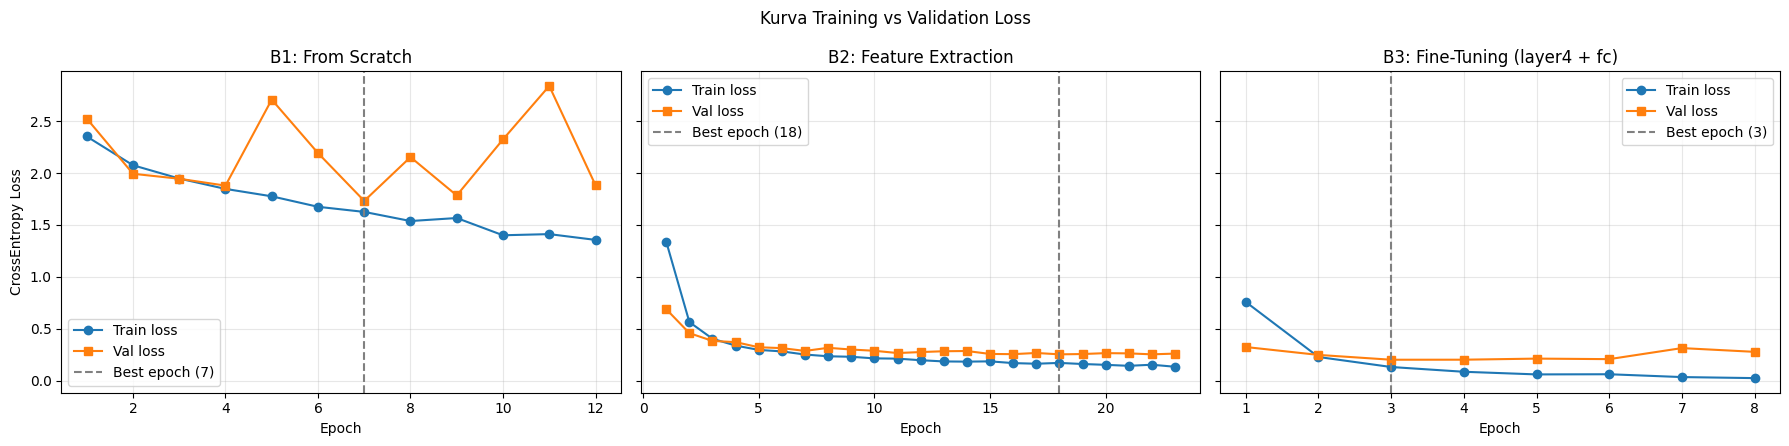

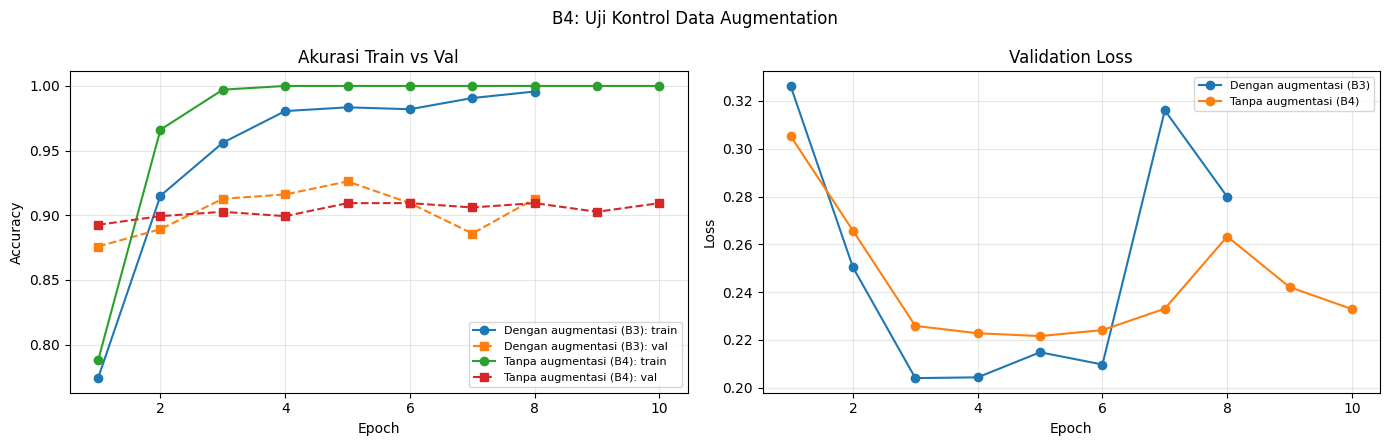

GAP TRAIN-VAL (akurasi train diukur tanpa augmentasi)
Eksperimen    Train acc     Val acc       Gap
B3            0.9827        0.9128        0.0699
B4_noaug      1.0000        0.9094        0.0906


In [11]:
# TABEL KONSOLIDASI & KURVA PEMBELAJARAN (C1)

# Tabel 1: metrik utama semua eksperimen
print("=" * 100)
print("TABEL KONSOLIDASI HASIL EKSPERIMEN")
print("=" * 100)
print(f"{'Kode':<12s}{'Strategi':<18s}{'Aug':<8s}{'Trainable':<14s}{'Epoch':<10s}"
      f"{'Waktu(s)':<10s}{'Train':<8s}{'Val':<8s}{'Gap':<8s}{'Test':<8s}{'Macro F1'}")
print("=" * 100)
for r in ALL_RESULTS.values():
    epoch_txt = f"{r['best_epoch']}/{r['epochs_run']}"
    print(f"{r['exp_id']:<12s}{r['strategy']:<18s}{str(r['augment']):<8s}{r['trainable_params']:<14,d}"
          f"{epoch_txt:<10s}{r['train_time_s']:<10.1f}{r['train_acc_best']:<8.3f}{r['val_acc_best']:<8.3f}"
          f"{r['gap_train_val']:<8.3f}{r['test_acc']:<8.3f}{r['test_macro_f1']:.4f}")
print()

# Tabel 2: arsitektur dan learning rate per eksperimen
print("=" * 100)
print("ARSITEKTUR & LEARNING RATE")
print("=" * 100)
print(f"{'Kode':<12s}{'Arsitektur':<20s}{'Learning rate'}")
print("=" * 100)
for r in ALL_RESULTS.values():
    print(f"{r['exp_id']:<12s}{r['arch']:<20s}{r['lr_groups']}")
print()

# Kurva train vs val loss: B1, B2, B3
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
titles = {"B1": "B1: From Scratch", "B2": "B2: Feature Extraction",
          "B3": "B3: Fine-Tuning (layer4 + fc)"}
for ax, exp in zip(axes, ["B1", "B2", "B3"]):
    h = ALL_HISTORY[exp]
    best = ALL_RESULTS[exp]["best_epoch"]
    ax.plot(h["epoch"], h["train_loss"], "o-", label="Train loss")
    ax.plot(h["epoch"], h["val_loss"],   "s-", label="Val loss")
    ax.axvline(best, color="gray", ls="--", label=f"Best epoch ({best})")
    ax.set_title(titles[exp])
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("CrossEntropy Loss")
plt.suptitle("Kurva Training vs Validation Loss")
plt.tight_layout()
plt.savefig(FIG_DIR / "loss_curves_B1_B2_B3.png", dpi=150)
plt.show()

# Kurva akurasi dan val loss: B3 (augmentasi) vs B4 (tanpa augmentasi)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for exp, label in [("B3", "Dengan augmentasi (B3)"), ("B4_noaug", "Tanpa augmentasi (B4)")]:
    h = ALL_HISTORY[exp]
    axes[0].plot(h["epoch"], h["train_acc"], "o-",  label=f"{label}: train")
    axes[0].plot(h["epoch"], h["val_acc"],   "s--", label=f"{label}: val")
    axes[1].plot(h["epoch"], h["val_loss"],  "o-",  label=label)
axes[0].set_title("Akurasi Train vs Val")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.suptitle("B4: Uji Kontrol Data Augmentation")
plt.tight_layout()
plt.savefig(FIG_DIR / "augmentation_B3_vs_B4.png", dpi=150)
plt.show()

# Tabel 3: gap yang adil (akurasi train diukur TANPA augmentasi)
set_seed()
clean_train_loader = DataLoader(PetDataset(train_df, eval_tf), batch_size=CONFIG["batch_size"],
                                shuffle=False, num_workers=CONFIG["num_workers"])

print("=" * 100)
print("GAP TRAIN-VAL (akurasi train diukur tanpa augmentasi)")
print("=" * 100)
print(f"{'Eksperimen':<14s}{'Train acc':<14s}{'Val acc':<14s}{'Gap'}")
print("=" * 100)
for exp, m in [("B3", model_B3), ("B4_noaug", model_B4)]:
    _, clean_tr_acc = run_epoch(m, clean_train_loader, nn.CrossEntropyLoss())
    ALL_RESULTS[exp]["train_acc_clean"] = round(clean_tr_acc, 4)
    ALL_RESULTS[exp]["gap_clean"] = round(clean_tr_acc - ALL_RESULTS[exp]["val_acc_best"], 4)
    print(f"{exp:<14s}{clean_tr_acc:<14.4f}{ALL_RESULTS[exp]['val_acc_best']:<14.4f}"
          f"{ALL_RESULTS[exp]['gap_clean']:.4f}")
save_all_logs()

**C2: Pembahasan Analisis Komparatif**

In [21]:
# Tabel 1: metrik utama per eksperimen
print("=" * 110)
print("METRIK UTAMA")
print("=" * 110)
print(f"{'Kode':<12s}{'Best/Total':<12s}{'Train acc':<11s}{'Val acc':<10s}{'Gap':<9s}{'Gap bersih':<12s}"
      f"{'Test acc':<10s}{'Macro F1':<10s}{'s/epoch':<9s}{'Trainable'}")
print("=" * 110)
for r in ALL_RESULTS.values():
    gap_clean = r.get("gap_clean")
    gap_clean_txt = f"{gap_clean:.4f}" if gap_clean is not None else "-"
    print(f"{r['exp_id']:<12s}{str(r['best_epoch']) + '/' + str(r['epochs_run']):<12s}"
          f"{r['train_acc_best']:<11.4f}{r['val_acc_best']:<10.4f}{r['gap_train_val']:<9.4f}"
          f"{gap_clean_txt:<12s}{r['test_acc']:<10.4f}{r['test_macro_f1']:<10.4f}"
          f"{r['time_per_epoch_s']:<9.1f}{r['trainable_params']:,}")
print()

# Tabel 2: kestabilitas val loss (untuk membandingkan B1, B2, B3, B4)
print("=" * 110)
print("KESTABILAN VALIDATION LOSS")
print("=" * 110)
print(f"{'Kode':<12s}{'Val loss min':<14s}{'Val loss max':<14s}{'Std':<10s}{'Naik dari epoch sebelumnya'}")
print("=" * 110)
for exp, h in ALL_HISTORY.items():
    vl = h["val_loss"]
    n_up = int((vl.diff() > 0).sum())
    print(f"{exp:<12s}{vl.min():<14.4f}{vl.max():<14.4f}{vl.std():<10.4f}{n_up} dari {len(vl) - 1} epoch")
print()


METRIK UTAMA
Kode        Best/Total  Train acc  Val acc   Gap      Gap bersih  Test acc  Macro F1  s/epoch  Trainable
B1          7/12        0.4396     0.3792    0.0604   -           0.3980    0.3775    14.0     11,181,642
B2          18/23       0.9381     0.8993    0.0388   -           0.9197    0.9195    12.8     5,130
B3          3/8         0.9561     0.9128    0.0434   0.0699      0.9164    0.9157    12.5     8,398,858
B4_noaug    5/10        1.0000     0.9094    0.0906   0.0906      0.9331    0.9325    8.8      8,398,858
B5          18/23       0.9935     0.9597    0.0338   -           0.9365    0.9361    13.2     1,142,202

KESTABILAN VALIDATION LOSS
Kode        Val loss min  Val loss max  Std       Naik dari epoch sebelumnya
B1          1.7316        2.8373        0.3658    4 dari 11 epoch
B2          0.2559        0.6900        0.0960    8 dari 22 epoch
B3          0.2040        0.3263        0.0509    3 dari 7 epoch
B4_noaug    0.2216        0.3053        0.0269    3 dari 9

Argumen:

Eksperimen menunjukkan ketimpangan performa antara pelatihan dari nol (B1) dan transfer learning (B2 & B3). Sesuai dengan konsep Slide 15, melatih ResNet-18 dari awal butuh data yang banyak (dan waktu yg lama?). Dengan hanya 1.390 data citra, B1 mengalami underfitting. Hal ini terbukti dari train accuracy yang rendah (0,4396), gap sempit (0,0604), dan validation loss yang berfluktuasi tajam. Akibatnya, akurasi test B1 hanya 39,8% dengan Macro F1 0,3775. Sebaliknya, B2 dan B3 melesat dengan akurasi test 92,0% dan 91,6% (Macro F1 0,9195 & 0,9157). Ini membuktikan bahwa transfer learning sangat efektif pada data terbatas karena model langsung re-use fitur visual ImageNet tanpa belajar dari nol.

Terdapat trade-off performa dan stabilitas antara feature extraction murni (B2) dan fine-tuning (B3) (Slide 16). Karena hanya melatih 5.130 parameter, kurva B2 jauh lebih halus dan stabil, mencapai epoch terbaik ke-18. Sebaliknya, B3 yang melatih 8.398.858 parameter mencapai validation loss minimum lebih rendah (0,2040 vs 0,2559), namun terlalu cepat dicapai pada epoch ke-3 dan segera mengalami overfitting (validation loss memburuk ke 0,3161 di epoch 7). Meskipun B3 memakai differential learning rate untuk mencegah catastrophic forgetting (Slide 28), selisih performa pengujian akhirnya dengan B2 sangat tipis (Macro F1 0,9157 vs 0,9195), yang secara praktis hanya setara dengan 1 gambar.

Pengujian augmentasi data (Slide 20) terbukti mampu meredam overfitting (Slide 28). Tanpa augmentasi (B4), model menghafal data latih hingga train accuracy absolut 1,0000, membuat gap generalisasinya melebar menjadi 9,06 poin persentase. Setelah transformasi augmentasi diaktifkan pada B3, efek regularisasinya sukses menekan gap tersebut menjadi 6,99 poin persentase. Namun, performa pengujian B4 (Macro F1 0,9325) justru sedikit lebih tinggi dari B3 (0,9157). Hal ini terjadi karena early stopping pada B4 sudah efektif mencegah overfitting, fitur pretrained model yang sudah kokoh, serta B3 yang berhenti terlalu cepat pada epoch 3 sebelum variasi augmentasi citranya sempat benar-benar dipelajari secara optimal oleh model.

**C3: Failure Analysis**

Note:

*   Model yang dianalisis dipilih berdasarkan **akurasi validasi** (B3), bukan test.
*   Semua gambar test yang salah diprediksi dikumpulkan, diurutkan dari confidence tertinggi (model yakin tapi salah), lalu disimpan ke `misclassified_B3.csv`.
*   Ditampilkan 8 gambar salah tebak, masing-masing dengan label asli, prediksi, dan confidence score (syarat C3: 5 sampai 8 sampel).
*   `prob_true` menunjukkan probabilitas kelas yang benar: tinggi berarti model hampir benar, rendah berarti model benar-benar keliru.
*   Dalam spesies sama vs antar spesies: menunjukkan apakah kesalahan terjadi di ras yang mirip (kucing tertukar kucing) atau antar spesies.
*   Confusion matrix dan tabel pasangan yang sering tertukar menjadi bukti untuk hipotesis ambigu visual antar ras (contoh: Birman vs Ragdoll, Pit Bull vs Staffordshire).
*   Tabel precision, recall, dan F1 **per kelas** menunjukkan ras mana yang paling lemah.


FAILURE ANALYSIS: MODEL B3
Total citra test         : 299
Prediksi benar           : 274
Prediksi salah           : 25
Akurasi test             : 91.6%

DAFTAR SEMUA KESALAHAN (diurutkan dari confidence tertinggi)
No   Label asli                  Prediksi                    Conf     Prob benar
1    Birman                      Ragdoll                     95.3%    3.3%
2    Staffordshire Bull Terrier  American Pit Bull Terrier   91.2%    7.2%
3    Ragdoll                     Birman                      91.1%    7.8%
4    American Pit Bull Terrier   Staffordshire Bull Terrier  88.2%    11.6%
5    American Pit Bull Terrier   Staffordshire Bull Terrier  86.3%    3.1%
6    Ragdoll                     Birman                      85.5%    14.2%
7    American Pit Bull Terrier   Staffordshire Bull Terrier  79.5%    19.9%
8    Birman                      Ragdoll                     72.7%    20.8%
9    Birman                      Ragdoll                     72.4%    27.2%
10   Abyssinian          

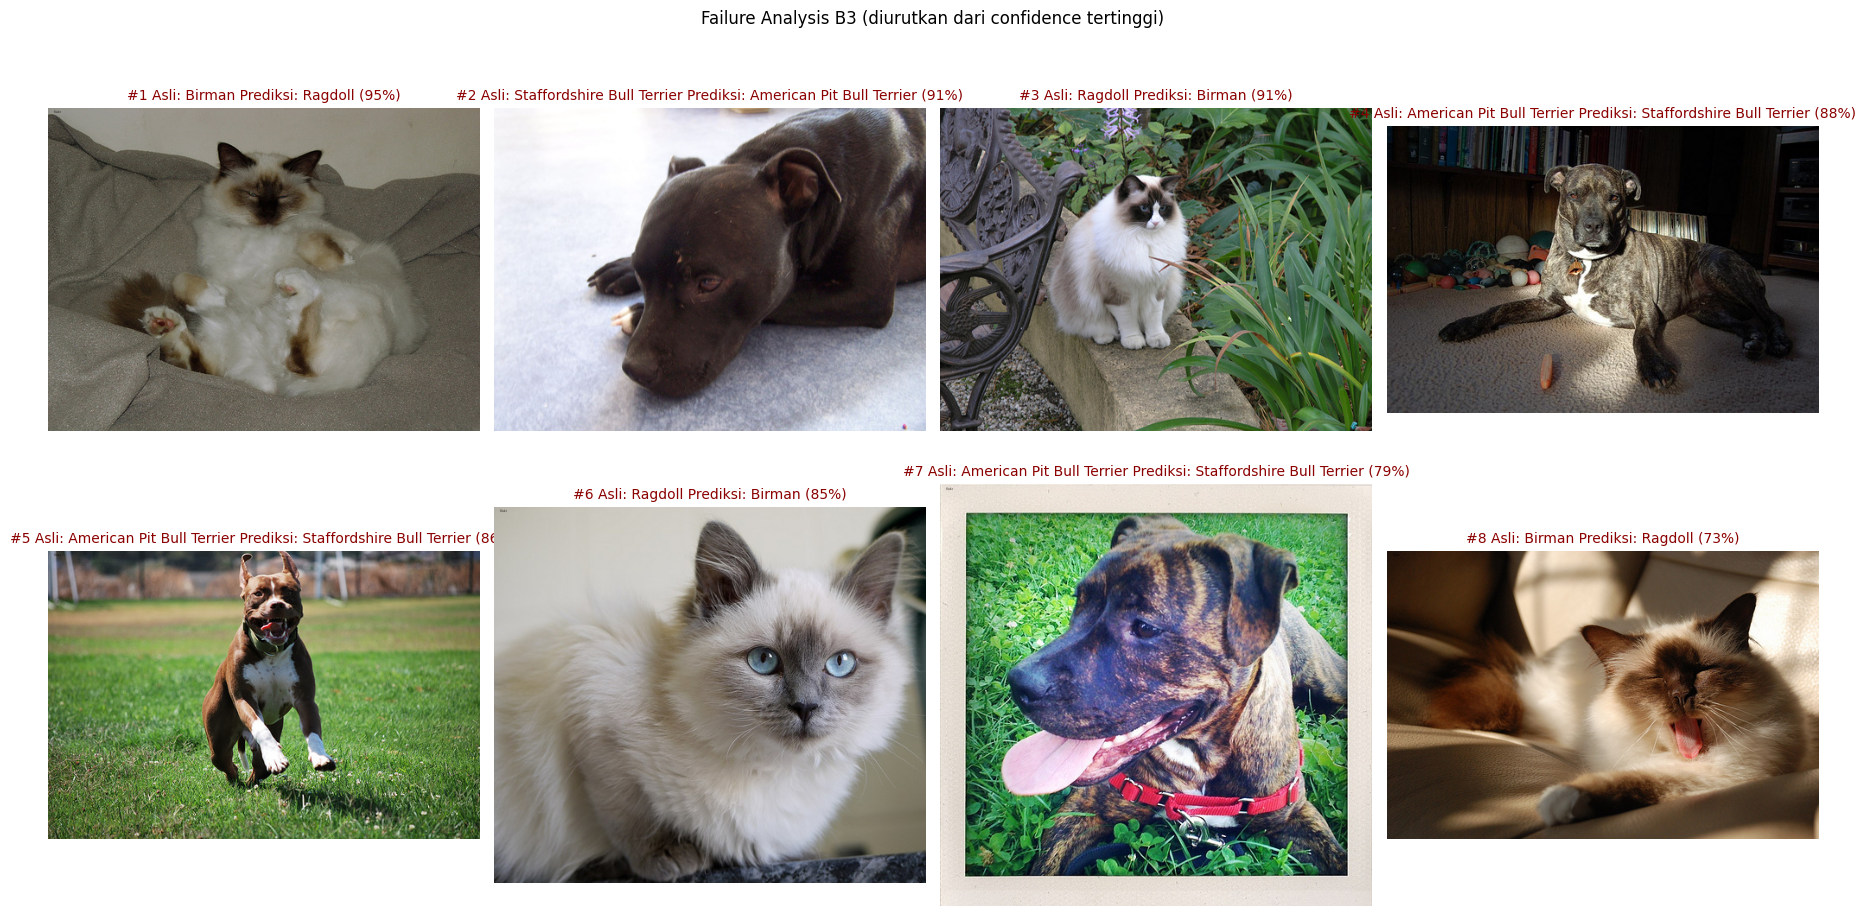

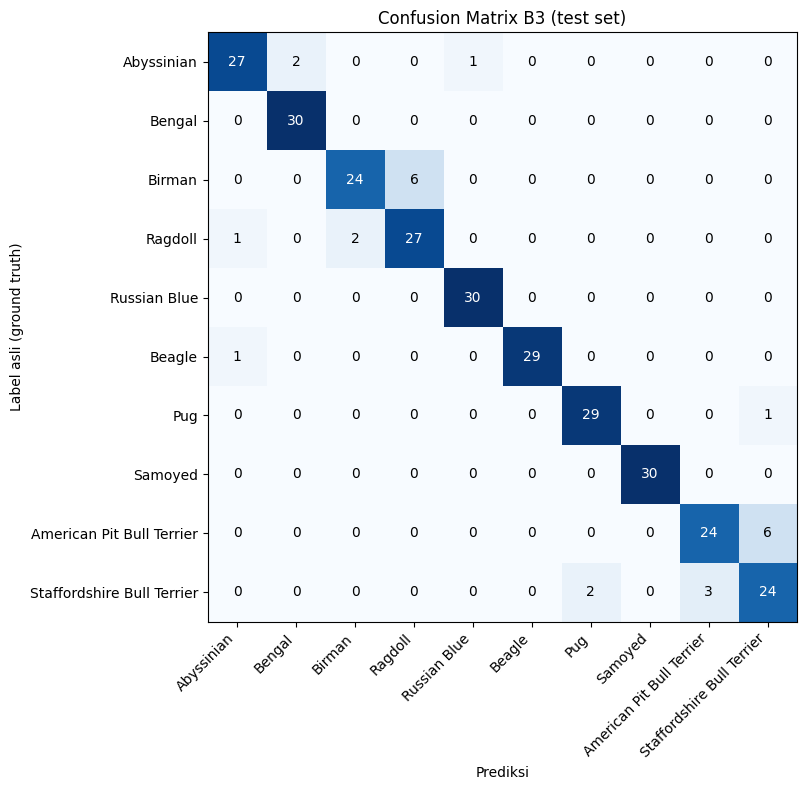

PASANGAN KELAS YANG PALING SERING TERTUKAR
Label asli                    Diprediksi sebagai            Jumlah
Birman                        Ragdoll                       6
American Pit Bull Terrier     Staffordshire Bull Terrier    6
Staffordshire Bull Terrier    American Pit Bull Terrier     3
Staffordshire Bull Terrier    Pug                           2
Ragdoll                       Birman                        2

PERFORMA PER KELAS (test set)
Ras                           Precision   Recall      F1          Support
Abyssinian                    0.931       0.900       0.915       30
Bengal                        0.938       1.000       0.968       30
Birman                        0.923       0.800       0.857       30
Ragdoll                       0.818       0.900       0.857       30
Russian Blue                  0.968       1.000       0.984       30
Beagle                        1.000       0.967       0.983       30
Pug                           0.935       0.967       0.951  

In [13]:
# Failure Analysis

# Model terbaik dipilih berdasarkan akurasi VALIDASI (bukan test)
best_exp = "B3"
y_true, y_pred, y_prob = pred_B3

# Kumpulkan semua gambar test yang salah diprediksi
wrong = np.where(y_true != y_pred)[0]

mis_df = pd.DataFrame({
    "path"     : test_df.loc[wrong, "path"].values,
    "true"     : [selected_classes[i] for i in y_true[wrong]],
    "pred"     : [selected_classes[i] for i in y_pred[wrong]],
    "conf_pred": y_prob[wrong, y_pred[wrong]].round(4),
    "prob_true": y_prob[wrong, y_true[wrong]].round(4),
}).sort_values("conf_pred", ascending=False).reset_index(drop=True)
mis_df.to_csv(LOG_DIR / f"misclassified_{best_exp}.csv", index=False)

# Jenis kesalahan: dalam spesies yang sama atau antar spesies
species_of = {c: ("cat" if c in cat_classes else "dog") for c in selected_classes}
mis_df["same_species"] = mis_df["true"].map(species_of) == mis_df["pred"].map(species_of)
n_same  = int(mis_df["same_species"].sum())
n_cross = len(mis_df) - n_same

# Tabel 1: ringkasan hasil test
print("=" * 80)
print(f"FAILURE ANALYSIS: MODEL {best_exp}")
print("=" * 80)
print(f"{'Total citra test':<25s}: {len(y_true)}")
print(f"{'Prediksi benar':<25s}: {len(y_true) - len(wrong)}")
print(f"{'Prediksi salah':<25s}: {len(wrong)}")
print(f"{'Akurasi test':<25s}: {(y_true == y_pred).mean():.1%}")
print()

# Tabel 2: semua kesalahan, diurutkan dari confidence tertinggi
print("=" * 80)
print("DAFTAR SEMUA KESALAHAN (diurutkan dari confidence tertinggi)")
print("=" * 80)
print(f"{'No':<5s}{'Label asli':<28s}{'Prediksi':<28s}{'Conf':<9s}{'Prob benar'}")
print("=" * 80)
for i, r in mis_df.iterrows():
    print(f"{i + 1:<5d}{r['true']:<28s}{r['pred']:<28s}{r['conf_pred']:<9.1%}{r['prob_true']:.1%}")
print()

# Tabel 3: kesalahan dalam spesies yang sama vs antar spesies
print("=" * 80)
print("JENIS KESALAHAN")
print("=" * 80)
print(f"{'Jenis':<42s}{'Jumlah':<10s}{'Persen'}")
print("=" * 80)
print(f"{'Dalam spesies sama (misal kucing-kucing)':<42s}{n_same:<10d}{n_same / len(mis_df):.1%}")
print(f"{'Antar spesies (kucing-anjing)':<42s}{n_cross:<10d}{n_cross / len(mis_df):.1%}")
print()

# Tampilkan 8 kesalahan dengan confidence tertinggi
n_show = min(8, len(mis_df))
fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for i, ax in enumerate(axes.flat):
    if i >= n_show:
        ax.axis("off")
        continue
    r = mis_df.iloc[i]
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    ax.set_title(f"#{i + 1} Asli: {r['true']} Prediksi: {r['pred']} ({r['conf_pred']:.0%})",
                 fontsize=10, color="darkred")
    ax.axis("off")
plt.suptitle(f"Failure Analysis {best_exp} (diurutkan dari confidence tertinggi)")
plt.tight_layout()
plt.savefig(FIG_DIR / f"failure_analysis_{best_exp}.png", dpi=150)
plt.show()

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(num_classes))
ax.set_xticklabels(selected_classes, rotation=45, ha="right")
ax.set_yticks(range(num_classes))
ax.set_yticklabels(selected_classes)
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xlabel("Prediksi")
ax.set_ylabel("Label asli (ground truth)")
ax.set_title(f"Confusion Matrix {best_exp} (test set)")
plt.tight_layout()
plt.savefig(FIG_DIR / f"confusion_matrix_{best_exp}.png", dpi=150)
plt.show()

# Tabel 4: pasangan kelas yang paling sering tertukar
pairs = [(cm[i, j], selected_classes[i], selected_classes[j])
         for i in range(num_classes) for j in range(num_classes)
         if i != j and cm[i, j] > 0]
pairs.sort(reverse=True)

print("=" * 80)
print("PASANGAN KELAS YANG PALING SERING TERTUKAR")
print("=" * 80)
print(f"{'Label asli':<30s}{'Diprediksi sebagai':<30s}{'Jumlah'}")
print("=" * 80)
for count, true_name, pred_name in pairs[:5]:
    print(f"{true_name:<30s}{pred_name:<30s}{count}")
print()

# Tabel 5: performa per kelas
report = classification_report(y_true, y_pred, target_names=selected_classes,
                               output_dict=True, zero_division=0)
print("=" * 80)
print("PERFORMA PER KELAS (test set)")
print("=" * 80)
print(f"{'Ras':<30s}{'Precision':<12s}{'Recall':<12s}{'F1':<12s}{'Support'}")
print("=" * 80)
for name in selected_classes:
    r = report[name]
    print(f"{name:<30s}{r['precision']:<12.3f}{r['recall']:<12.3f}{r['f1-score']:<12.3f}{int(r['support'])}")
print("=" * 80)
m = report["macro avg"]
print(f"{'Macro avg':<30s}{m['precision']:<12.3f}{m['recall']:<12.3f}{m['f1-score']:<12.3f}{int(m['support'])}")

Analisa Failure:

Berdasarkan hasil evaluasi test set pada model B3, terdapat 25 prediksi yang salah dari total 299 citra. Mayoritas kesalahan (96%) terjadi di dalam spesies yang sama, dan beberapa ras spesifik saling tertukar. Berikut adalah analisis beberapa sampel:


1.   Pada sampel pertama ini, model sangat yakin menebak gambar sebagai Ragdoll dengan confidence 95,3%, padahal probabilitas kelas aslinya (Birman) hanya tersisa 3,3%. Secara visual, gambar menampilkan kucing yang sedang telentang di atas sofa. Posisi ini membuat bagian kakinya terlipat sehingga hanya sebagian kecil cakarnya yang terlihat di ujung bawah frame. Diduga model menebak salah karena terlalu bergantung pada pola "warna", dilihat dari bulu tubuh krem dengan area wajah dan telinga gelap yang memang dimiliki oleh kedua ras tersebut secara identik. Karena salah satu penanda pembeda utama Birman (berupa "sarung tangan" putih di area cakar) tidak terekspos dengan baik akibat posenya, model akhirnya lebih condong memprediksinya sebagai Ragdoll. Dugaan ini sangat didukung oleh matriks konfusi, di mana kesalahan kelas Birman ke Ragdoll adalah yang paling mendominasi (6 kasus). Selain itu, pada sampel kegagalan Birman yang lain (seperti sampel #8), fitur kakinya juga tampak tidak kelihatan.
2.   Sampel #2 (Prediksi: American Pit Bull Terrier | Fakta: Staffordshire Bull Terrier)
Di sampel kedua, model keliru memprediksi American Pit Bull Terrier dengan confidence 91,2%, sementara probabilitas benarnya hanya 7,2%. Gambar ini diambil dengan sudut terlalu zoom in ekstrem pada wajah anjing berwarna cokelat gelap yang sedang menempel di lantai. Akibatnya, proporsi tubuh, lebar dada, dan postur kakinya terpotong sepenuhnya dari tangkapan kamera. Dari observasi ini, diduga kuat model gagal membedakan kedua ras karena kehilangan konteks anatomi tubuh anjing secara menyeluruh. Jika hanya dilihat secara close-up, struktur wajah, tulang rahang, dan bentuk telinga Staffordshire memang sangat mirip dengan Pit Bull.

**C4: Rekomendasi Rekayasa dan Batasan Eksperimen**

Berdasarkan eksperimen pada skala data terbatas (1.400 citra, 10 kelas), feature extraction murni (B2) direkomendasikan untuk meminimalkan parameter (5.130 parameter) dan menekan risiko *overfitting*, meski tidak efisien dari sisi waktu total karena butuh 308,4 detik (konvergen di epoch 18) dibanding fine-tuning (B3) yang hanya butuh 107,2 detik. Dari sisi performa, B2 dan B3 sebenarnya setara dan tidak dapat dibedakan dari variasi acak (B3 sedikit unggul di validasi dengan val acc 0,9128 dan val loss 0,2040, sedangkan B2 unggul tipis di test Macro F1 0,9195 vs 0,9157). Namun, jika tolok ukurnya adalah performa maksimal, penggunaan arsitektur EfficientNet-B0 (B5) terbukti memberikan hasil tertinggi (val acc 0,9597 dan test Macro F1 0,9361) dengan parameter terlatih yang jauh lebih ramping (1,14 juta) dibanding B3. Kondisi berlakunya rekomendasi ini terbatas pada skala data kecil dengan domain yang beririsan dengan ImageNet, resolusi 224 x 224, dan perangkat GPU kelas T4, di mana pengembangan sebaiknya dimulai dari feature extraction sebagai baseline cepat sebelum beralih ke fine-tuning atau arsitektur lain jika performa mentok (Slide 16, 29).

Sebagai transparansi ilmiah, studi ini memiliki sejumlah limitasi penting: pengujian sepenuhnya bergantung pada single seed (seed 42) tanpa k-fold cross-validation sehingga sensitif terhadap variasi splitting; ukuran test set sangat kecil (299 citra) sehingga selisih beberapa gambar tidak konklusif; model baseline (B1) dihentikan dini pada epoch 12 saat train loss masih turun; learning rate scheduler tidak digunakan (Slide 29); hyperparameter tidak dituning spesifik per eksperimen; waktu per epoch tercemar oleh biaya augmentasi CPU; serta memori GPU aktual tidak diukur secara kuantitatif.

In [22]:
# ARSITEKTUR PEMBANDING (EFFICIENTNET-B0)
# Konfigurasi terbaik (B3: fine-tuning) dijalankan di arsitektur lain

model_B5, res_B5, pred_B5 = run_experiment(
    exp_id="B5", strategy="finetune", arch="efficientnet_b0", augment=True,
    description="EfficientNet-B0 pretrained, stage terakhir + classifier dilatih (differential LR)",
)

EKSPERIMEN B5: EfficientNet-B0 pretrained, stage terakhir + classifier dilatih (differential LR)
Strategi            : finetune
Arsitektur          : efficientnet_b0
Augmentasi          : True
Trainable params    : 1,142,202 / 4,020,358
Learning rate       : {'last_block': 0.0001, 'head': 0.001}

Epoch   Train Loss  Train Acc   Val Loss    Val Acc     Waktu    Catatan
1       1.0463      0.758       0.3215      0.896       14.7s    best
2       0.3055      0.901       0.2249      0.926       16.4s    best
3       0.2146      0.932       0.1762      0.933       12.7s    best
4       0.1799      0.942       0.1624      0.943       15.1s    best
5       0.1521      0.946       0.1556      0.936       13.0s    best
6       0.1245      0.955       0.1408      0.946       15.3s    best
7       0.1093      0.966       0.1585      0.940       12.9s    
8       0.0941      0.971       0.1482      0.943       12.8s    
9       0.0827      0.979       0.1394      0.943       16.9s    best
10     

In [23]:
# DOWNLOAD REQUIREMENTS DAN HASIL

import zipfile
import importlib.metadata as md
from google.colab import files

# Tulis requirements.txt dari versi yang terpasang (satu paket per baris)
packages = ["torch", "torchvision", "numpy", "pandas", "matplotlib", "scikit-learn", "pillow", "tqdm"]
req_path = OUTPUT_DIR / "requirements.txt"
with open(req_path, "w") as f:
    for p in packages:
        f.write(f"{p}=={md.version(p)}")

print("=" * 60)
print("REQUIREMENTS.TXT")
print("=" * 60)
print(req_path.read_text())

# Kemas log dan gambar menjadi satu ZIP (tanpa file model .pt)
zip_path = "/content/hasil_tugas05.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for folder in [LOG_DIR, FIG_DIR]:
        for file in folder.rglob("*"):
            if file.is_file():
                z.write(file, file.relative_to(OUTPUT_DIR))
    z.write(req_path, "requirements.txt")

# Daftar isi ZIP untuk pengecekan
print("=" * 60)
print("ISI ZIP")
print("=" * 60)
with zipfile.ZipFile(zip_path) as z:
    for name in z.namelist():
        print(name)
print()

print(f"ZIP siap diunduh: {zip_path}")
files.download(zip_path)


REQUIREMENTS.TXT
torch==2.11.0+cu130torchvision==0.26.0+cu130numpy==2.1.3pandas==2.2.3matplotlib==3.10.0scikit-learn==1.6.1pillow==11.3.0tqdm==4.67.3
ISI ZIP
logs/results_summary.csv
logs/data_split.csv
logs/history_all.csv
logs/misclassified_B3.csv
logs/results_summary.json
logs/config.json
figures/confusion_matrix_B3.png
figures/sample_per_class.png
figures/augmentation_B3_vs_B4.png
figures/failure_analysis_B3.png
figures/augmentation_preview.png
figures/loss_curves_B1_B2_B3.png
requirements.txt

ZIP siap diunduh: /content/hasil_tugas05.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving images.webp to images.webp

PREDIKSI: images.webp
Peringkat   Ras                           Probabilitas
1           Russian Blue                  99.6%
2           Abyssinian                    0.3%
3           Ragdoll                       0.0%


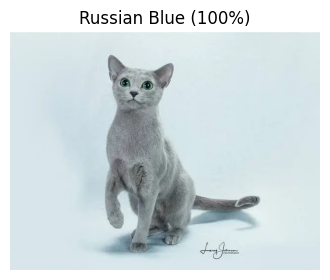

In [16]:
# Demo test case by upload gambar

from google.colab import files

def predict_image(image_path, model, top_k=3):
    model.eval()
    img = Image.open(image_path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)

    with torch.no_grad():
        prob = torch.softmax(model(x), dim=1)[0].cpu()
    top_p, top_i = prob.topk(top_k)

    print("")
    print(f"PREDIKSI: {Path(image_path).name}")
    print("=" * 60)
    print(f"{'Peringkat':<12s}{'Ras':<30s}{'Probabilitas'}")
    print("=" * 60)
    for rank, (p, i) in enumerate(zip(top_p, top_i), start=1):
        print(f"{rank:<12d}{selected_classes[i]:<30s}{p:.1%}")

    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"{selected_classes[top_i[0]]} ({top_p[0]:.0%})")
    plt.axis("off")
    plt.show()

# Upload satu atau lebih gambar, lalu prediksi dengan model terbaik (B3)
uploaded = files.upload()
for name in uploaded:
    predict_image(name, model_B3)
    print()


# Pernyataan Integritas Akademik & Penggunaan AI (AI Disclosure Statement)

Sesuai Bab 7 Pedoman Penugasan (Bobot 5%):

- **Model/Alat AI yang Digunakan:** Kiro (asisten AI untuk pengembangan perangkat lunak) berbasis model Claude dari Anthropic. <Tambahkan alat lain di sini hanya jika benar-benar dipakai.>

- **Ruang Lingkup Pemanfaatan:**
  1. Menjelaskan konsep dasar CNN, Batch Normalization, residual connection, transfer learning, augmentasi, dan catastrophic forgetting sebagai bahan pemahaman.
  3. Membantu debugging (misalnya galat variabel yang tidak terdefinisi) dan menyiapkan template README.md, requirements.txt, serta kerangka laporan.
  4. Memberi umpan balik atas draf jawaban Bagian A dan analisis Bagian C
  5. Membantu membuat code download hasil

- **Metode Verifikasi Mandiri:**
  1. Seluruh kode dijalankan sendiri di lingkungan GPU, dan hasil keluaran tiap sel diperiksa.
  2. Jumlah parameter terlatih diperiksa sebelum training: B1 11.181.642, B2 5.130, dan B3 8.398.858 parameter, sesuai tips implementasi pada soal.
  3. Pembagian data stratified 70/15/15 (1.390/298/299 citra) diperiksa memakai pengecekan overlap antar split (`isdisjoint` dan `assert`) untuk memastikan tidak ada kebocoran data.
  4. Eksperimen dijalankan ulang dengan seed yang sama (42), dan hasil metriknya identik dengan run sebelumnya.
  5. Seluruh angka pada laporan dicocokkan dengan berkas log mentah (`results_summary.csv`/`.json`, `history_all.csv`, `misclassified_B3.csv`).
  6. Hipotesis pada failure analysis disusun dengan melihat langsung citra yang salah diprediksi dan membandingkannya dengan confusion matrix serta tabel performa per kelas.
  7. Konsep pada Bagian A diperiksa terhadap slide Sesi 05.
